# Maze dataset examples

Each sample is an `(input, target)` pair:

- `input` `(3, H, W)`: channel 0 = maze (**1 = passage, 0 = wall**), channel 1 = start, channel 2 = exit
- `target` `(1, H, W)`: 1 on the shortest path from start to exit

In the images: black = wall, white = passage, blue = path, green = start, red = exit.

In [1]:
import subprocess
import sys
from collections import Counter
from pathlib import Path

REPO_URL = "https://github.com/yoshi0428/maze-generalization.git"
BRANCH = "main"

if "google.colab" in sys.modules:
    # Colab: clone the repo (or update an existing clone) under /content.
    root = Path("/content/maze-generalization")
    if root.is_dir():
        subprocess.run(["git", "-C", str(root), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(root)], check=True)
else:
    # Local: the notebook runs from the repo root or notebooks/.
    root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

sys.path.insert(0, str(root / "src"))

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

from dataset import MazeDataset, make_test_datasets, make_train_dataset, stratified_split
from generators import GENERATORS

print("available generators:", list(GENERATORS))

available generators: ['dfs', 'prim', 'kruskal', 'eller', 'aldous_broder', 'wilson', 'recursive_division', 'hunt_and_kill', 'sidewinder']


In [2]:
def print_binary(maze):
    """Print the raw 0/1 values."""
    for row in maze.squeeze().int().tolist():
        print(" ".join(map(str, row)))


def render(x, y=None):
    """RGB image of a sample: black wall, white passage, blue path, green start, red exit."""
    img = x[0, :, :, None].repeat(1, 1, 3).clone()
    if y is not None:
        img[y[0] == 1] = torch.tensor([0.4, 0.6, 1.0])
    img[x[1] == 1] = torch.tensor([0.0, 0.8, 0.0])
    img[x[2] == 1] = torch.tensor([0.9, 0.0, 0.0])
    return img


def show(*mazes, titles=(), ncols=3):
    """Plot mazes as images in a grid (2D maze or an RGB image from render())."""
    ncols = min(ncols, len(mazes))
    nrows = -(-len(mazes) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(mazes):
            ax.imshow(mazes[i].squeeze(), cmap="gray")
            ax.set_title(titles[i] if i < len(titles) else "")
    plt.show()

## A small maze from each generator, as raw 0/1

In [3]:
for name in GENERATORS:
    x, y = MazeDataset([name], size=9, num_samples=1)[0]
    print(f"{name}  maze shape={tuple(x[0].shape)}")
    print_binary(x[0])
    print()

dfs  maze shape=(11, 11)
0 0 0 0 0 0 0 0 0 0 0
0 1 0 1 1 1 1 1 1 1 0
0 1 0 1 0 1 0 0 0 1 0
0 1 1 1 0 1 0 1 1 1 0
0 1 0 0 0 1 0 1 0 0 0
0 1 1 1 0 1 0 1 1 1 0
0 0 0 1 0 1 0 0 0 1 0
0 1 1 1 0 1 0 1 1 1 0
0 1 0 0 0 1 0 0 0 1 0
0 1 1 1 0 1 1 1 0 1 0
0 0 0 0 0 0 0 0 0 0 0

prim  maze shape=(11, 11)
0 0 0 0 0 0 0 0 0 0 0
0 1 0 1 1 1 1 1 0 1 0
0 1 0 0 0 1 0 0 0 1 0
0 1 0 1 1 1 1 1 1 1 0
0 1 0 0 0 1 0 0 0 1 0
0 1 1 1 0 1 1 1 0 1 0
0 0 0 1 0 0 0 1 0 0 0
0 1 0 1 0 1 1 1 1 1 0
0 1 0 1 0 0 0 1 0 0 0
0 1 1 1 1 1 1 1 1 1 0
0 0 0 0 0 0 0 0 0 0 0

kruskal  maze shape=(11, 11)
0 0 0 0 0 0 0 0 0 0 0
0 1 1 1 1 1 1 1 1 1 0
0 1 0 0 0 1 0 1 0 1 0
0 1 1 1 0 1 0 1 0 1 0
0 1 0 1 0 1 0 0 0 0 0
0 1 0 1 0 1 1 1 1 1 0
0 1 0 0 0 1 0 0 0 1 0
0 1 0 1 0 1 0 1 0 1 0
0 1 0 1 0 1 0 1 0 0 0
0 1 0 1 1 1 1 1 1 1 0
0 0 0 0 0 0 0 0 0 0 0

eller  maze shape=(11, 11)
0 0 0 0 0 0 0 0 0 0 0
0 1 0 1 1 1 1 1 1 1 0
0 1 0 0 0 0 0 1 0 0 0
0 1 0 1 1 1 0 1 1 1 0
0 1 0 0 0 1 0 1 0 0 0
0 1 1 1 1 1 1 1 0 1 0
0 0 0 0 0 1 0 0 0 1 0
0 1 0 1 0 

## Input channels and target of one sample, as raw 0/1

maze
0 0 0 0 0 0 0 0 0 0 0
0 1 0 1 1 1 1 1 1 1 0
0 1 0 1 0 1 0 0 0 1 0
0 1 1 1 0 1 0 1 1 1 0
0 1 0 0 0 1 0 1 0 0 0
0 1 1 1 0 1 0 1 1 1 0
0 0 0 1 0 1 0 0 0 1 0
0 1 1 1 0 1 0 1 1 1 0
0 1 0 0 0 1 0 0 0 1 0
0 1 1 1 0 1 1 1 0 1 0
0 0 0 0 0 0 0 0 0 0 0

start
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 1 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0

exit
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 1 0
0 0 0 0 0 0 0 0 0 0 0

target path
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 0 0 0 0
0 0 0 0 0 0 0 1 1 1 0
0 0 0 0 0 0 0 0 0 1 0
0 0 0 0 0 0 0 0 0 1 0
0 0 0 0 0 0 0 0 0 1 0
0 0 0 0 0 0 0 0 0 1 0
0 0 0 0 0 0 0 0 0 0 0



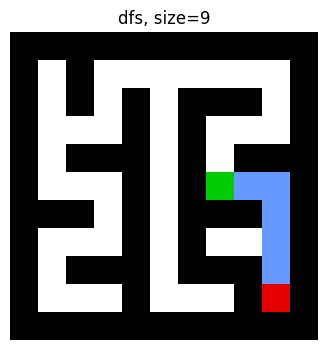

In [4]:
x, y = MazeDataset(["dfs"], size=9, num_samples=1)[0]
for name, channel in [("maze", x[0]), ("start", x[1]), ("exit", x[2]), ("target path", y[0])]:
    print(name)
    print_binary(channel)
    print()
show(render(x, y), titles=["dfs, size=9"])

## Training set: 1/3 per generator, stratified train/val split

In [5]:
train = make_train_dataset(["dfs", "prim", "kruskal"], size=63, num_samples=30_000)
train_set, val_set = stratified_split(train, val_fraction=0.1)

def mix(subset):
    return Counter(train.generator_names[train.labels[i]] for i in subset.indices)

print("full :", len(train), Counter(train.generator_names[g] for g in train.labels))
print("train:", len(train_set), mix(train_set))
print("val  :", len(val_set), mix(val_set))

# Single-generator training set.
dfs_only = make_train_dataset("dfs", size=127, num_samples=1_000)
print("dfs only:", dfs_only.generator_names, "input shape", tuple(dfs_only[0][0].shape))

full : 30000 Counter({'dfs': 10000, 'prim': 10000, 'kruskal': 10000})


train: 27000 Counter({'dfs': 9000, 'prim': 9000, 'kruskal': 9000})
val  : 3000 Counter({'dfs': 1000, 'kruskal': 1000, 'prim': 1000})
dfs only: ['dfs'] input shape (3, 129, 129)


generator=dfs input=(3, 65, 65) target=(1, 65, 65) dtype=torch.float32


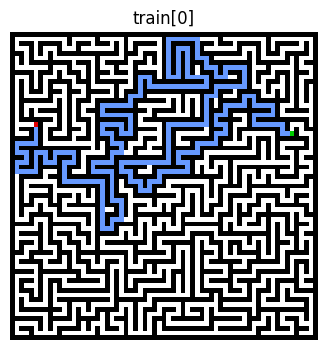

In [6]:
x, y = train[0]
print(f"generator={train.generator_names[train.labels[0]]} "
      f"input={tuple(x.shape)} target={tuple(y.shape)} dtype={x.dtype}")
show(render(x, y), titles=["train[0]"])

In [7]:
inputs, targets = next(iter(DataLoader(train_set, batch_size=32, shuffle=True)))
print("inputs:", tuple(inputs.shape), "targets:", tuple(targets.shape))

inputs: (32, 3, 65, 65) targets: (32, 1, 65, 65)


## Test sets

Test generators must differ from the training ones, otherwise the check raises:

In [8]:
try:
    make_test_datasets("dfs", sizes=63, num_samples=10, train_generators=train.generator_names)
except ValueError as e:
    print("ValueError:", e)

ValueError: Generators ['dfs'] are also used for training; test mazes must come from unseen generators


Unseen generators at several sizes, with 10% of walls removed:

In [9]:
tests = make_test_datasets(
    generators=["eller", "wilson", "hunt_and_kill"],
    sizes=[63, 127, 255],
    num_samples=1_000,
    train_generators=train.generator_names,
    wall_removal=0.1,
)
for size, ds in tests.items():
    print(size, len(ds), ds.generator_names, tuple(ds[0][0].shape))

63 1000 ['eller', 'wilson', 'hunt_and_kill'] (3, 65, 65)


127 1000 ['eller', 'wilson', 'hunt_and_kill'] (3, 129, 129)


255 1000 ['eller', 'wilson', 'hunt_and_kill'] (3, 257, 257)


walls opened: 96
path length: 133 -> 49


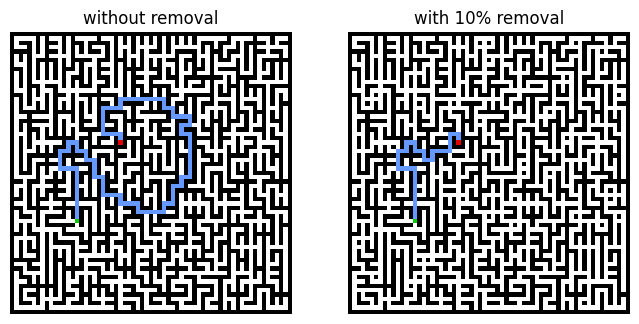

In [10]:
# Same maze with and without wall removal.
ds = tests[63]
perfect = MazeDataset(ds.generator_names, ds.size, ds.num_samples, seed=ds.seed)
before, after = perfect[0], ds[0]
print("walls opened:", int((after[0][0] - before[0][0]).sum()))
print("path length:", int(before[1].sum()), "->", int(after[1].sum()))
show(render(*before), render(*after), titles=["without removal", "with 10% removal"])

## One 65x65 maze per generator

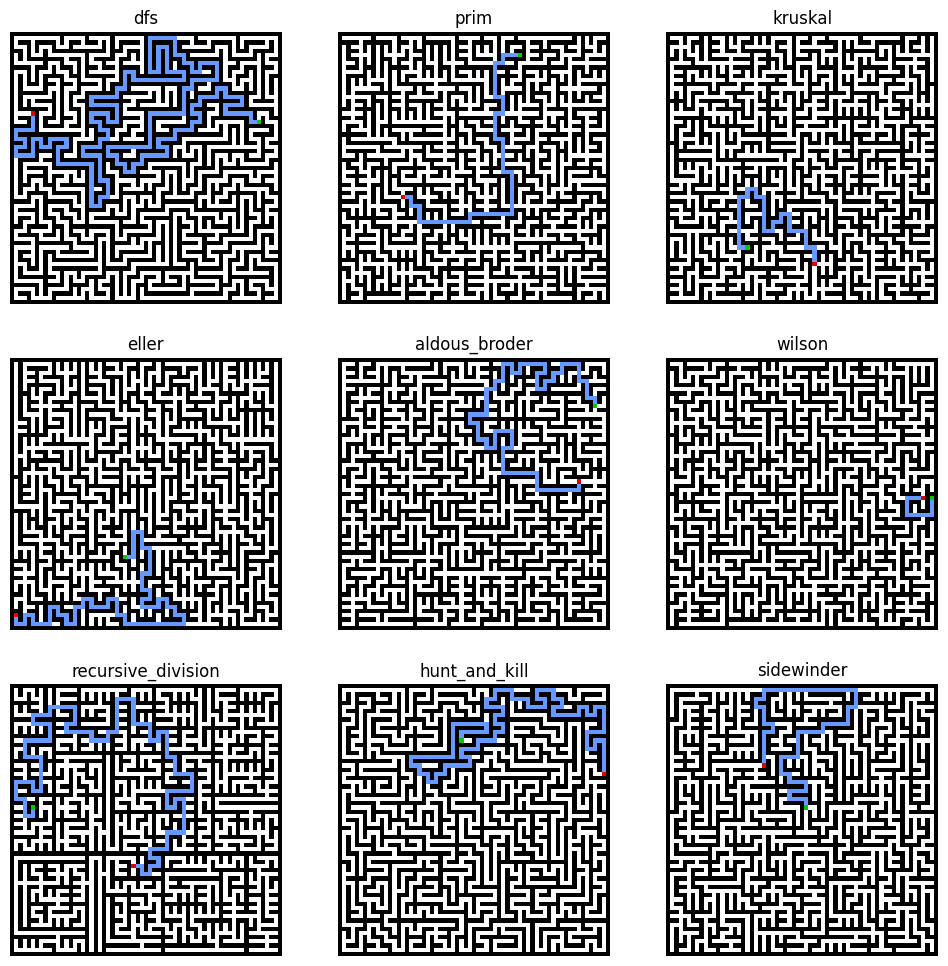

In [11]:
show(*(render(*MazeDataset([name], 63, 1)[0]) for name in GENERATORS), titles=list(GENERATORS))